--- ETAPA 1: Diagnóstico ---
Determinante da matriz A: 3.00

--- ETAPA 2: Redistribuição ---
Ônibus necessários por região para atender 100% da demanda:
Norte: 14 | Sul: 19 | Leste: 18 | Oeste: 21
Total necessário: 72 ônibus

Matriz de Transformação T (Soma das colunas = 1):
[[0.85 0.   0.   0.  ]
 [0.   0.8  0.   0.  ]
 [0.   0.2  1.   0.  ]
 [0.15 0.   0.   1.  ]]
Soma das colunas: [1. 1. 1. 1.]

Distribuição Atual vs Nova Frota:
Norte: 12 -> 10
Sul:   24 -> 19
Leste: 14 -> 19
Oeste: 22 -> 24
Total: 72 -> 72 (preservado)


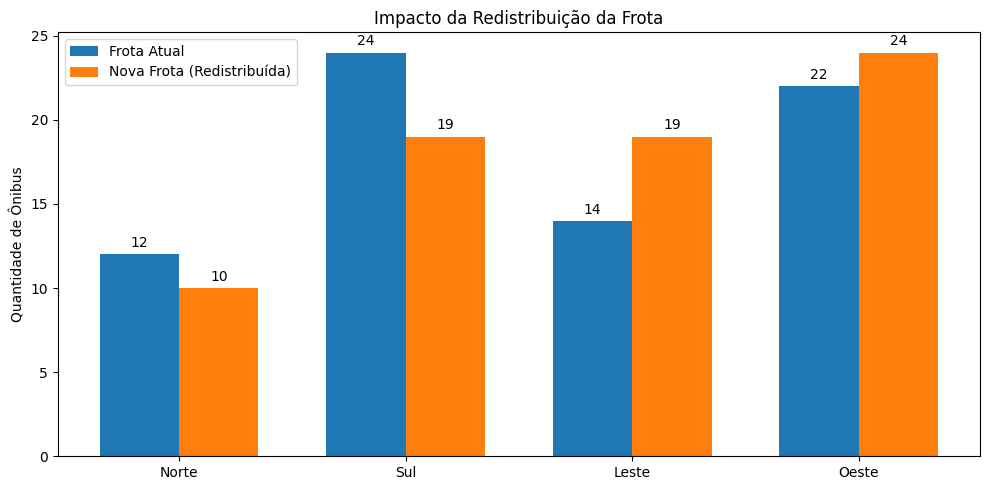

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# ETAPA 1 - Diagnóstico Atual (Sistema Linear)
# ==========================================
print("--- ETAPA 1: Diagnóstico ---")

# Variáveis: x1 (Norte), x2 (Sul), x3 (Leste), x4 (Oeste)
# Equações do Relatório I:
# 1) x1 + x2 + x3 + x4 = 72
# 2) x1 + 2*x2 + x4 = 76
# 3) x2 + 2*x3 = 52
# 4) x1 + x3 + 2*x4 = 76

# Matriz A e vetor b
A = np.array([
    [1, 1, 1, 1],
    [1, 2, 0, 1],
    [0, 1, 2, 0],
    [1, 0, 1, 2]
], dtype=float)

b = np.array([72, 76, 52, 76], dtype=float)

# Investigando o determinante
det_A = np.linalg.det(A)
print(f"Determinante da matriz A: {det_A:.2f}")

if np.isclose(det_A, 0):
    print("O determinante é zero! O sistema é indeterminado (infinitas soluções).")
    print("Isso significa que apenas com esses dados não é possível determinar uma única distribuição exata.")

    # Resolvendo usando mínimos quadrados para achar uma solução que melhor se ajusta (pseudo-inversa)
    # Como o sistema é indeterminado, essa é uma das soluções possíveis que atende às restrições.
    solucao = np.linalg.lstsq(A, b, rcond=None)[0]
    print(f"Uma distribuição possível (solução via mínimos quadrados):")
    print(f"Norte: {solucao[0]:.1f} | Sul: {solucao[1]:.1f} | Leste: {solucao[2]:.1f} | Oeste: {solucao[3]:.1f}")
    print("Nota: Como o número de ônibus deve ser inteiro, faremos o arredondamento na Etapa 2.")

# ==========================================
# ETAPA 2 - Redistribuição
# ==========================================
print("\n--- ETAPA 2: Redistribuição ---")

# Demanda e Capacidade
demanda = np.array([560, 760, 720, 840])
capacidade = 40
onibus_necessarios = demanda / capacidade

print("Ônibus necessários por região para atender 100% da demanda:")
print(f"Norte: {onibus_necessarios[0]:.0f} | Sul: {onibus_necessarios[1]:.0f} | Leste: {onibus_necessarios[2]:.0f} | Oeste: {onibus_necessarios[3]:.0f}")
print(f"Total necessário: {sum(onibus_necessarios):.0f} ônibus")

# Distribuição atual aproximada (arredondada da Etapa 1)
# x1(Norte)=12, x2(Sul)=24, x3(Leste)=14, x4(Oeste)=22 (ajustado para fechar os 72)
# Nota: Você pode usar os valores exatos que achou no Colab
frota_atual = np.array([12, 24, 14, 22])

# Matriz de Transformação T (Redistribuição)
# Vamos supor que:
# - Norte envia 2 ônibus para Oeste
# - Sul envia 4 ônibus para Leste
# - Mantemos o resto onde está para manter a soma 72.
# T deve ser construída de forma que T * frota_atual = nova_frota
# Vamos criar uma matriz identidade e alterar os fluxos
T = np.eye(4)
T[3, 0] = 0.15  # Norte envia 15% para Oeste
T[0, 0] = 0.85  # Norte fica com 85%
T[2, 1] = 0.20  # Sul envia 20% para Leste
T[1, 1] = 0.80  # Sul fica com 80%

# Verificando se a matriz é válida (soma das colunas = 1, todos positivos)
print("\nMatriz de Transformação T (Soma das colunas = 1):")
print(np.round(T, 2))
print(f"Soma das colunas: {np.sum(T, axis=0)}")

# Aplicando a transformação
nova_frota = T @ frota_atual

# Arredondando para inteiros e ajustando para garantir que a soma seja 72
nova_frota_int = np.round(nova_frota).astype(int)
diferenca = 72 - sum(nova_frota_int)
if diferenca != 0:
    # Adiciona ou remove a diferença na região que mais precisa (Oeste, por exemplo)
    nova_frota_int[3] += diferenca

print("\nDistribuição Atual vs Nova Frota:")
print(f"Norte: {frota_atual[0]} -> {nova_frota_int[0]}")
print(f"Sul:   {frota_atual[1]} -> {nova_frota_int[1]}")
print(f"Leste: {frota_atual[2]} -> {nova_frota_int[2]}")
print(f"Oeste: {frota_atual[3]} -> {nova_frota_int[3]}")
print(f"Total: {sum(frota_atual)} -> {sum(nova_frota_int)} (preservado)")

# Gráfico Comparativo
regioes = ['Norte', 'Sul', 'Leste', 'Oeste']
x = np.arange(len(regioes))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))
rects1 = ax.bar(x - width/2, frota_atual, width, label='Frota Atual', color='#1f77b4')
rects2 = ax.bar(x + width/2, nova_frota_int, width, label='Nova Frota (Redistribuída)', color='#ff7f0e')

ax.set_ylabel('Quantidade de Ônibus')
ax.set_title('Impacto da Redistribuição da Frota')
ax.set_xticks(x)
ax.set_xticklabels(regioes)
ax.legend()

ax.bar_label(rects1, padding=3)
ax.bar_label(rects2, padding=3)

plt.tight_layout()
plt.show()